# SC11 Step 4 - fair baseline comparison
This notebook is a worked teaching example. The baseline always predicts
the most common training label; the ANN predictions are the saved Step 3
outputs. Both are compared on exactly the same validation and test rows.
This is **not** a water-safety test.

In [1]:
from pathlib import Path
import sys

# VS Code may start a notebook in the repository root or in notebooks/.
ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / 'src' / 'compare_baseline.py').is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        'Open the SC11 repository folder in VS Code and create '
        'src/compare_baseline.py first.'
    )
sys.path.insert(0, str(ROOT))
print('Project folder:', ROOT)
print('Step 3 metrics exist:',
      (ROOT / 'data' / 'reports' / 'step3_ann_metrics.csv').is_file())

Project folder: d:\sample_project\SC11-Water-Quality-Potability-Example
Step 3 metrics exist: True


## Run the same reproducible comparison
The Python file checks that saved ANN predictions match the Step 2 split
row-for-row. It stops with an error if files are missing or mismatched.

In [2]:
from src import compare_baseline
metrics, comparison = compare_baseline.main()

SC11 STEP 4 - FAIR BASELINE COMPARISON
Training rows: 1788; class counts: {1: 894, 0: 894}
Majority baseline always predicts: 0

Both methods use exactly the same validation/test rows.
     split            method  rows  accuracy  precision  recall  f1_score
validation Majority baseline   384    0.5000     0.0000  0.0000    0.0000
validation        Step 3 ANN   384    0.5443     0.5415  0.5781    0.5592
      test Majority baseline   384    0.5000     0.0000  0.0000    0.0000
      test        Step 3 ANN   384    0.6276     0.6310  0.6146    0.6227

ANN minus baseline (positive means ANN is higher):
     split    metric  baseline    ann  ann_minus_baseline
validation  accuracy       0.5 0.5443              0.0443
validation precision       0.0 0.5415              0.5415
validation    recall       0.0 0.5781              0.5781
validation  f1_score       0.0 0.5592              0.5592
      test  accuracy       0.5 0.6276              0.1276
      test precision       0.0 0.6310        

## Read the comparison
`ann_minus_baseline` is a score difference, not a percentage improvement.
A positive number means the ANN scored higher for that metric on the same split.

,split,method,rows,accuracy,precision,recall,f1_score
0,validation,Majority baseline,384,0.5000,0.0000,0.0000,0.0000
1,validation,Step 3 ANN,384,0.5443,0.5415,0.5781,0.5592
2,test,Majority baseline,384,0.5000,0.0000,0.0000,0.0000
3,test,Step 3 ANN,384,0.6276,0.6310,0.6146,0.6227


,split,metric,baseline,ann,ann_minus_baseline
0,validation,accuracy,0.5,0.5443,0.0443
1,validation,precision,0.0,0.5415,0.5415
2,validation,recall,0.0,0.5781,0.5781
3,validation,f1_score,0.0,0.5592,0.5592
4,test,accuracy,0.5,0.6276,0.1276
5,test,precision,0.0,0.6310,0.6310
6,test,recall,0.0,0.6146,0.6146
7,test,f1_score,0.0,0.6227,0.6227


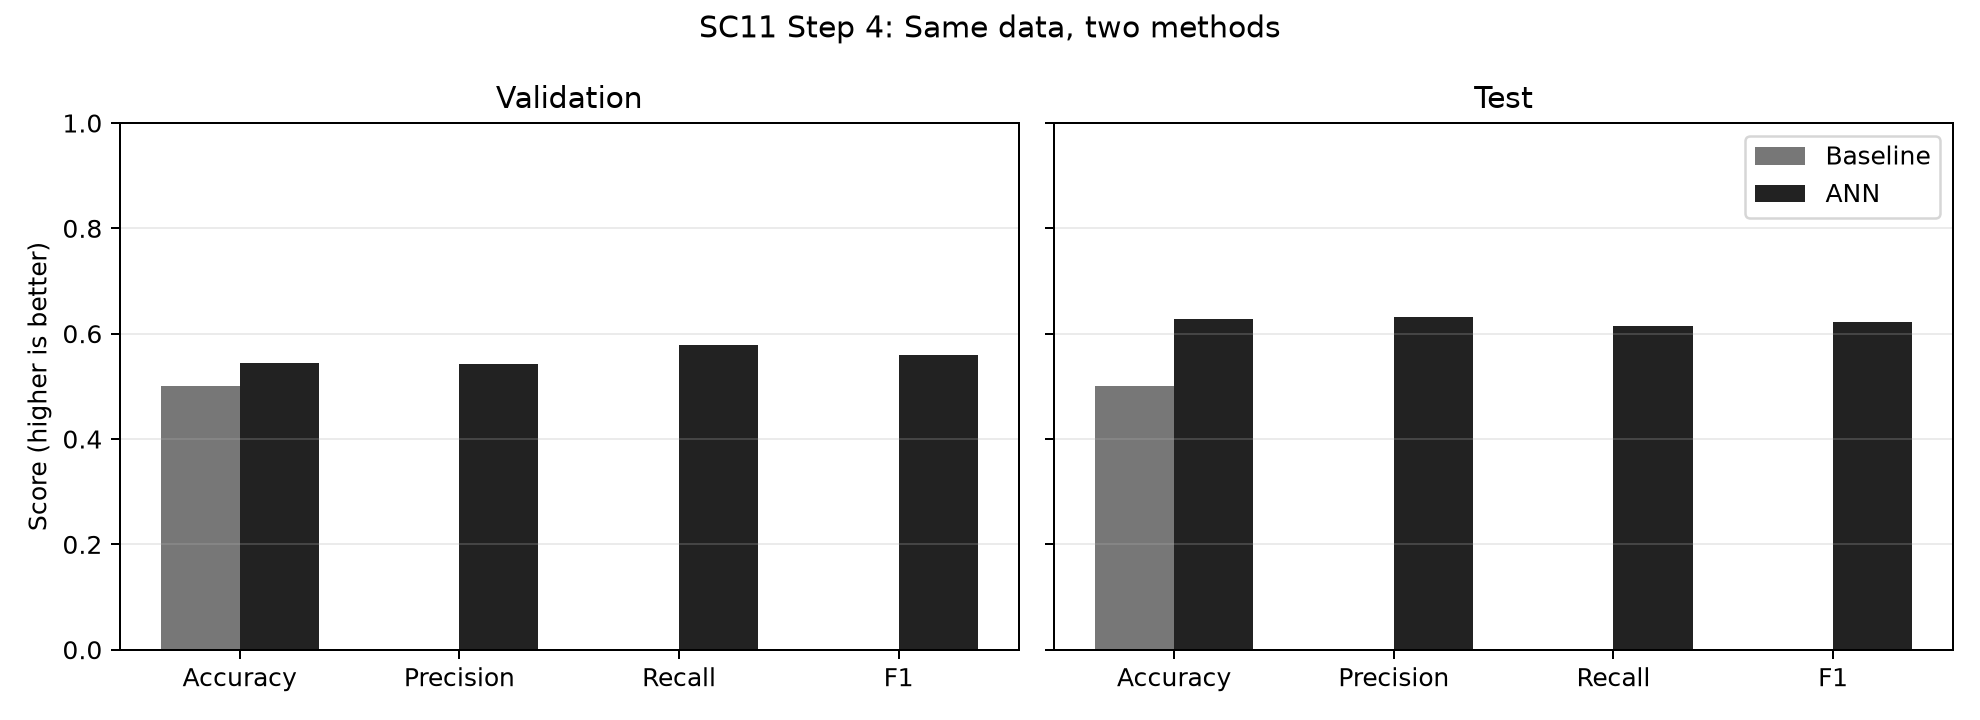

In [3]:
from IPython.display import display, Image
display(metrics)
display(comparison)
display(Image(filename=str(ROOT / 'results' / 'step4_baseline_vs_ann.png')))

## Inspect a few paired predictions
The baseline and ANN columns must refer to the same original row and known
label. Do not treat generated testing scenarios as real labelled samples.

In [4]:
import pandas as pd
paired = pd.read_csv(ROOT / 'data' / 'reports' / 'step4_test_paired_predictions.csv')
display(
    paired[['Potability', 'baseline_prediction', 'ann_prediction']].head(10)
)
print('Test rows compared:', len(paired))

,Potability,baseline_prediction,ann_prediction
0,1,0,1
1,1,0,1
2,1,0,0
3,1,0,1
4,0,0,0
5,1,0,0
6,0,0,0
7,0,0,1
8,1,0,1
9,1,0,0


Test rows compared: 384


## Explain the result in your own words
Record the baseline rule, training-only label count, validation/test sizes,
all four metrics, limits of the dataset, and the fact that a classifier
cannot certify drinking water. Adapt this workflow - not the SC11 code -
for your own allotted project.